## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "juan sebastian pulgarin moreno" 
carnet = "1000103178"


## 1) Descripción del problema **[1 pts]**


Una empresa debe administrar tareas técnicas según su prioridad y conectar varios dispositivos utilizando la menor cantidad total de cable, donde se mirara la prioridad de cada servidor, procesara mejor las tareas, y donde se analisara cada dispositivo 

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.

requerimientos funcionales 
RF-1:cargar las 6 tareas con el nombre y prioridad 

RF-2:contruir un MAX -Heap con Max

RF-3:mostrar el arreglo inicial, el Max Head

RF-4: extraer la tarea de mayor prioridad dos veces , mostrando la 
tarea procesada y heap tras cada extracción

RF-5:cargar  los 6 dispositivos con ID y posición (X,y)



requerimientos no funcionales 

RNF-1: todo el desarrollo en un unico Nobebook llamado parcial 

RNF-2:no usar head ni funciones de librerias que calculen el MST

RNF-3:lenguaje python , con una hora

RNF-4:codigo simple y funcional y nombres al español 

RNF-5:ejecución del programa corriendo 







## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.


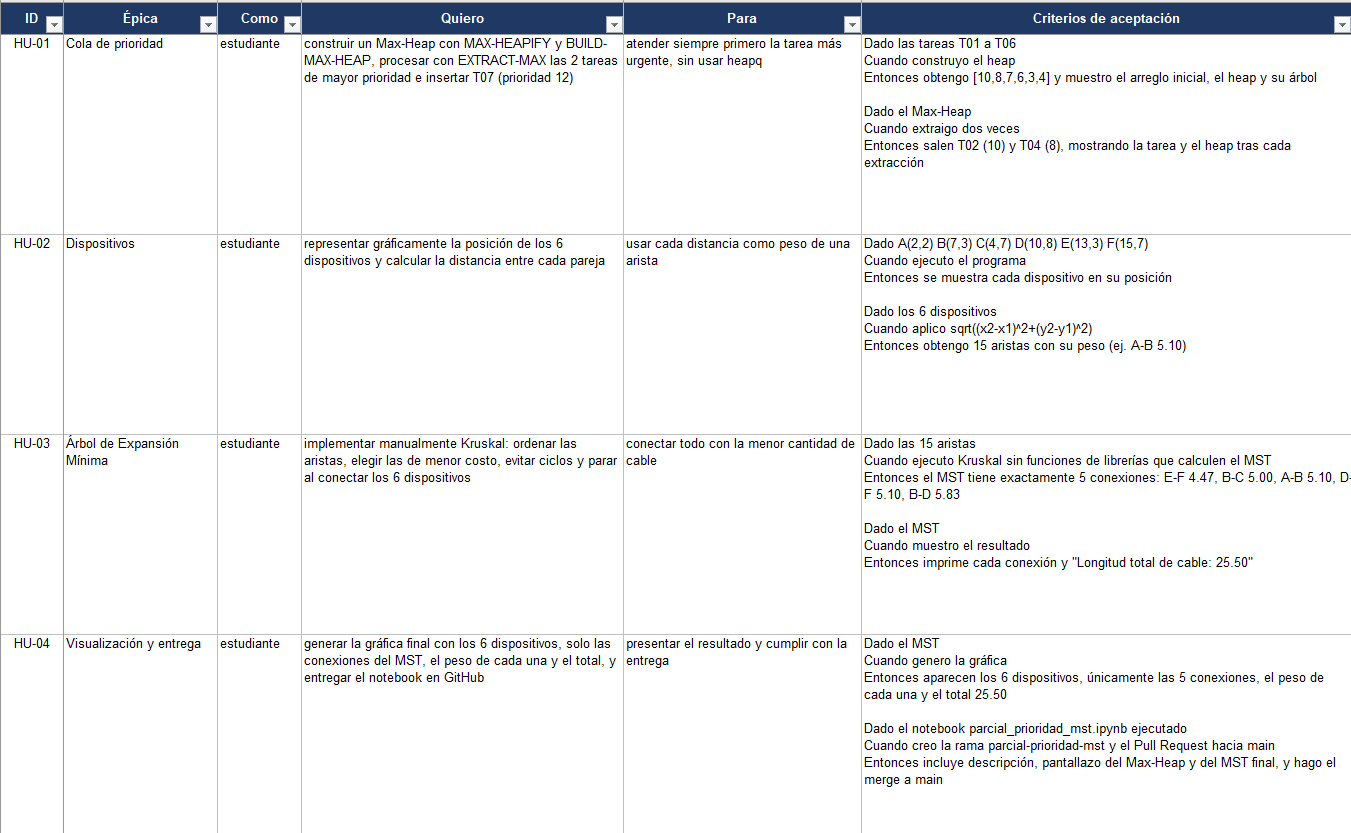

## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

Adjunta imagen y descríbelo claramente.

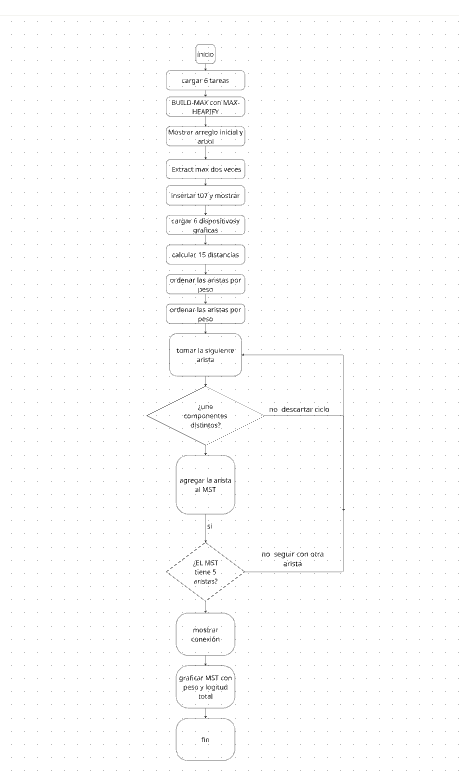



este es el diagrama de flujo donde se analisa los diferentes casos y operaciones del problema 

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica


mejor caso
dado que es el minimo trabajo posible dado de que las primeras 5 aristas ya forman el arbol 

el mejor caso es el 0, 1 ,32
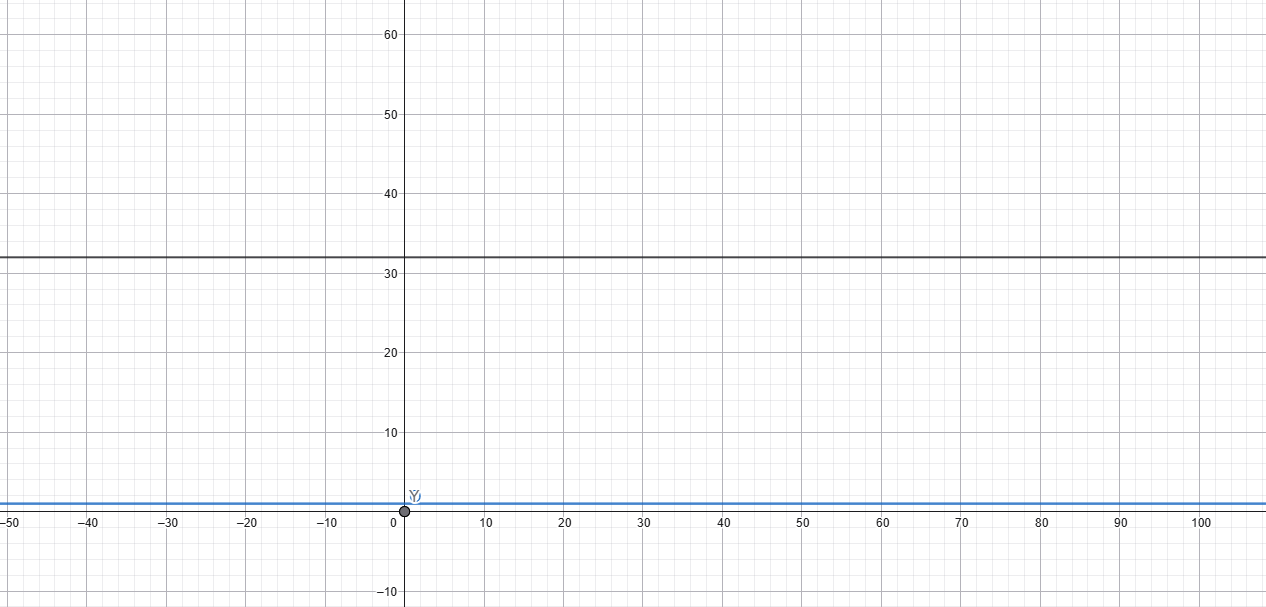







peor caso 


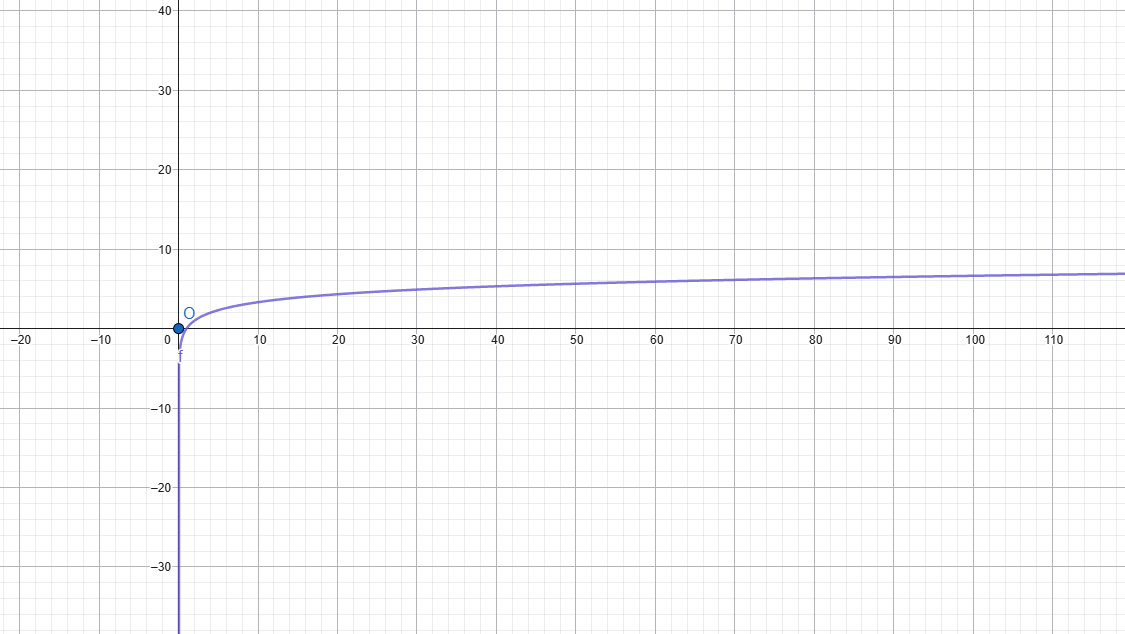


y el peor caso es log2(x)


es el maximo trabajo posible ya que el elemento recorre todo el arbol 

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [ ]:
#ejercicio 1
tareas = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor", 10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar cámara", 8),
    ("T05", "Generar respaldo", 3),
    ("T06", "Configurar alarma", 7),
]

def prioridad(h, i):
    return h[i][2]

def max_heapify(h, i, n):
    izq, der, mayor = 2*i + 1, 2*i + 2, i
    if izq < n and prioridad(h, izq) > prioridad(h, mayor):
        mayor = izq
    if der < n and prioridad(h, der) > prioridad(h, mayor):
        mayor = der
    if mayor != i:
        h[i], h[mayor] = h[mayor], h[i]
        max_heapify(h, mayor, n)

def build_max_heap(h):
    for i in range(len(h)//2 - 1, -1, -1):
        max_heapify(h, i, len(h))

def mostrar(h):
    print([f"{t[0]}({t[2]})" for t in h])

def mostrar_arbol(h):
    niveles = len(bin(len(h))) - 2
    ancho = 10 * 2**(niveles - 1)
    i = 0
    for n in range(niveles):
        fila = h[i:i + 2**n]
        print("".join(f"{t[0]}({t[2]})".center(ancho // 2**n) for t in fila))
        i += 2**n
heap = tareas[:]
print("Arreglo inicial:")
mostrar(heap)

build_max_heap(heap)
print("Max-Heap resultante:")
mostrar(heap)

print("Árbol del Heap:")
mostrar_arbol(heap)
#ejercico 2
def extract_max(h):
    mayor = h[0]
    h[0] = h[-1]
    h.pop()
    max_heapify(h, 0, len(h))
    return mayor

def insertar(h, tarea):
    h.append(tarea)
    i = len(h) - 1
    while i > 0 and prioridad(h, (i - 1)//2) < prioridad(h, i):
        h[i], h[(i - 1)//2] = h[(i - 1)//2], h[i]
        i = (i - 1)//2
for _ in range(2):
    t = extract_max(heap)
    print("Tarea procesada:", t[0], "-", t[1], "- Prioridad", t[2])
    print("Heap:", end=" ")
    mostrar(heap)
    print()

insertar(heap, ("T07", "falla en sistema    ", 12))
print("Heap después de insertar T07:")
mostrar(heap)
mostrar_arbol(heap)

#ejercicio 3
dispositivos = {
    "A": ("servidor", 2, 2),
    "B": ("cámara", 7, 3),
    "C": ("sensor", 4, 7),
    "D": ("alarmaa", 10, 8),
    "E": ("router", 13, 3),
    "F": ("panell", 15, 7),
}

def dibujar(conexiones):
    EX, EY = 4, 2                     
    ancho, alto = 16*EX + 1, 9*EY + 1
    lienzo = [[" "]*ancho for _ in range(alto)]
    for u, v, d in conexiones:          
        x1, y1 = dispositivos[u][1]*EX, dispositivos[u][2]*EY
        x2, y2 = dispositivos[v][1]*EX, dispositivos[v][2]*EY
        pasos = max(abs(x2 - x1), abs(y2 - y1))
        for k in range(pasos + 1):
            x = round(x1 + (x2 - x1)*k/pasos)
            y = round(y1 + (y2 - y1)*k/pasos)
            lienzo[y][x] = "*"
    for id_, (nombre, x, y) in dispositivos.items():  
        lienzo[y*EY][x*EX] = id_
    for fila in range(alto - 1, -1, -1):
        print("".join(lienzo[fila]).rstrip())


print("Posición de los dispositivos:")
dibujar([])
ids = sorted(dispositivos)
aristas = []   # (peso, u, v)
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        u, v = ids[i], ids[j]
        x1, y1 = dispositivos[u][1:]
        x2, y2 = dispositivos[v][1:]
        d = ((x2 - x1)**2 + (y2 - y1)**2) ** 0.5
        aristas.append((d, u, v))
        print(f"{u} - {v} : {d:.2f}")

#ejercicio 4
orden = aristas[:]
for i in range(len(orden)):
    for j in range(len(orden) - 1 - i):
        if orden[j][0] > orden[j + 1][0]:
            orden[j], orden[j + 1] = orden[j + 1], orden[j]


padre = {d: d for d in ids}
def encontrar(x):
    while padre[x] != x:
        x = padre[x]
    return x

mst, total = [], 0
for d, u, v in orden:               
    ru, rv = encontrar(u), encontrar(v)
    if ru != rv:                    
        padre[rv] = ru
        mst.append((u, v, d))
        total += d
    if len(mst) == len(ids) - 1:   
        break


## 7) Tests aplicados **[15 pts]**

In [2]:
#ejercicio 1
tareas = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor", 10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar cámara", 8),
    ("T05", "Generar respaldo", 3),
    ("T06", "Configurar alarma", 7),
]

def prioridad(h, i):
    return h[i][2]

def max_heapify(h, i, n):
    izq, der, mayor = 2*i + 1, 2*i + 2, i
    if izq < n and prioridad(h, izq) > prioridad(h, mayor):
        mayor = izq
    if der < n and prioridad(h, der) > prioridad(h, mayor):
        mayor = der
    if mayor != i:
        h[i], h[mayor] = h[mayor], h[i]
        max_heapify(h, mayor, n)

def build_max_heap(h):
    for i in range(len(h)//2 - 1, -1, -1):
        max_heapify(h, i, len(h))

def mostrar(h):
    print([f"{t[0]}({t[2]})" for t in h])

def mostrar_arbol(h):
    niveles = len(bin(len(h))) - 2
    ancho = 10 * 2**(niveles - 1)
    i = 0
    for n in range(niveles):
        fila = h[i:i + 2**n]
        print("".join(f"{t[0]}({t[2]})".center(ancho // 2**n) for t in fila))
        i += 2**n
heap = tareas[:]
print("Arreglo inicial:")
mostrar(heap)

build_max_heap(heap)
print("\nMax-Heap resultante:")
mostrar(heap)

print("\nÁrbol del Heap:")
mostrar_arbol(heap)

# ejercicio 2
def extract_max(h):
    mayor = h[0]
    h[0] = h[-1]
    h.pop()
    max_heapify(h, 0, len(h))
    return mayor

def insertar(h, tarea):
    h.append(tarea)
    i = len(h) - 1
    while i > 0 and prioridad(h, (i - 1)//2) < prioridad(h, i):
        h[i], h[(i - 1)//2] = h[(i - 1)//2], h[i]
        i = (i - 1)//2
for _ in range(2):
    t = extract_max(heap)
    print("Tarea procesada:", t[0], "-", t[1], "- Prioridad", t[2])
    print("Heap:", end=" ")
    mostrar(heap)
    print()

insertar(heap, ("T07", "Falla en sistema contra incendios", 12))
print("Heap después de insertar T07:")
mostrar(heap)
mostrar_arbol(heap)

# ejercicio 3
dispositivos = {
    "A": ("Servidor", 2, 2),
    "B": ("Cámara", 7, 3),
    "C": ("Sensor", 4, 7),
    "D": ("Alarma", 10, 8),
    "E": ("Router", 13, 3),
    "F": ("Panel", 15, 7),
}

def dibujar(conexiones):
    EX, EY = 4, 2                       
    ancho, alto = 16*EX + 1, 9*EY + 1
    lienzo = [[" "]*ancho for _ in range(alto)]
    for u, v, d in conexiones:          
        x1, y1 = dispositivos[u][1]*EX, dispositivos[u][2]*EY
        x2, y2 = dispositivos[v][1]*EX, dispositivos[v][2]*EY
        pasos = max(abs(x2 - x1), abs(y2 - y1))
        for k in range(pasos + 1):
            x = round(x1 + (x2 - x1)*k/pasos)
            y = round(y1 + (y2 - y1)*k/pasos)
            lienzo[y][x] = "*"
    for id_, (nombre, x, y) in dispositivos.items():   
        lienzo[y*EY][x*EX] = id_
    for fila in range(alto - 1, -1, -1):
        print("".join(lienzo[fila]).rstrip())


print("Posición de los dispositivos:")
dibujar([])
ids = sorted(dispositivos)
aristas = []   
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        u, v = ids[i], ids[j]
        x1, y1 = dispositivos[u][1:]
        x2, y2 = dispositivos[v][1:]
        d = ((x2 - x1)**2 + (y2 - y1)**2) ** 0.5
        aristas.append((d, u, v))
        print(f"{u} - {v} : {d:.2f}")

# ejercicio4
orden = aristas[:]
for i in range(len(orden)):
    for j in range(len(orden) - 1 - i):
        if orden[j][0] > orden[j + 1][0]:
            orden[j], orden[j + 1] = orden[j + 1], orden[j]

padre = {d: d for d in ids}
def encontrar(x):
    while padre[x] != x:
        x = padre[x]
    return x

mst, total = [], 0
for d, u, v in orden:               
    ru, rv = encontrar(u), encontrar(v)
    if ru != rv:                    
        padre[rv] = ru
        mst.append((u, v, d))
        total += d
    if len(mst) == len(ids) - 1:    
        break

for u, v, d in mst:
    print(f"{u} - {v} : {d:.2f}")
print(f"Longitud total de cable: {total:.2f}")
print("Conexiones en el MST:", len(mst))

# ejercicio 5
dibujar(mst)
for u, v, d in mst:
    print(f"{u} - {v} : {d:.2f}")
print(f"Longitud total de cable: {total:.2f}")


# test de cada punto
def es_max_heap(h):
    return all(prioridad(h, (i - 1)//2) >= prioridad(h, i) for i in range(1, len(h)))

print("\n========== TESTS ==========")

#ejercicio 1
h = tareas[:]
build_max_heap(h)
assert es_max_heap(h), "no cumple la propiedad Max-Heap"
assert sorted(h) == sorted(tareas), "se perdieron o cambiaron tareas"
assert [t[0] for t in h] == ["T02", "T04", "T06", "T01", "T05", "T03"]
assert h[0][2] == 10                                   
for caso in ([1], [1, 2, 3, 4, 5], [5, 4, 3, 2, 1], [3, 3, 3, 3]):  
    x = [("X", "t", p) for p in caso]
    build_max_heap(x)
    assert es_max_heap(x)
print("Punto 1: OK  (propiedad Max-Heap, contenido, raíz y casos de borde)")

# ejercicio 2
h = tareas[:]
build_max_heap(h)
t1 = extract_max(h); assert t1[0] == "T02" and es_max_heap(h) and len(h) == 5
t2 = extract_max(h); assert t2[0] == "T04" and es_max_heap(h) and len(h) == 4
insertar(h, ("T07", "Falla en sistema contra incendios", 12))
assert es_max_heap(h) and len(h) == 5
assert h[0][0] == "T07"                                
assert [t[2] for t in h] == [12, 7, 3, 4, 6]
salida = [extract_max(h)[2] for _ in range(len(h))]   
assert salida == [12, 7, 6, 4, 3]
print("Punto 2: OK  (orden de extracción, heap válido tras cada paso, inserción)")

# ejercicio3
assert len(aristas) == 15                              
for d, u, v in aristas:
    esperado = ((dispositivos[v][1] - dispositivos[u][1])**2 +
                (dispositivos[v][2] - dispositivos[u][2])**2) ** 0.5
    assert abs(d - esperado) < 1e-9 and d > 0
dist = {(u, v): d for d, u, v in aristas}
assert round(dist[("A", "B")], 2) == 5.10
assert round(dist[("B", "C")], 2) == 5.00
assert round(dist[("E", "F")], 2) == 4.47
assert round(dist[("A", "F")], 2) == 13.93
print("Punto 3: OK  (15 aristas, fórmula y valores conocidos)")

# ---- Test Punto 4--
assert len(mst) == 5                                   
assert all(orden[i][0] <= orden[i + 1][0] for i in range(len(orden) - 1))   
assert round(total, 2) == 25.50
assert len({frozenset((u, v)) for u, v, d in mst}) == 5   

def conecta_y_sin_ciclos(aristas_sel):
    p = {x: x for x in ids}
    def f(x):
        while p[x] != x:
            x = p[x]
        return x
    for u, v, d in aristas_sel:
        if f(u) == f(v):
            return False                               
        p[f(v)] = f(u)
    return len({f(x) for x in ids}) == 1               

assert conecta_y_sin_ciclos(mst)

mejor = None
for mascara in range(1 << len(aristas)):
    if bin(mascara).count("1") == 5:
        sel = [(u, v, d) for k, (d, u, v) in enumerate(aristas) if mascara >> k & 1]
        if conecta_y_sin_ciclos(sel):
            s = sum(e[2] for e in sel)
            if mejor is None or s < mejor:
                mejor = s
assert abs(mejor - total) < 1e-9, "existe un árbol más barato"
print("Punto 4: OK  (5 conexiones, sin ciclos, conectado, mínimo por fuerza bruta)")

# ejercicion 5
usados = {x for u, v, d in mst for x in (u, v)}
assert usados == set(dispositivos)   

Arreglo inicial:
['T01(6)', 'T02(10)', 'T03(4)', 'T04(8)', 'T05(3)', 'T06(7)']

Max-Heap resultante:
['T02(10)', 'T04(8)', 'T06(7)', 'T01(6)', 'T05(3)', 'T03(4)']

Árbol del Heap:
                T02(10)                 
       T04(8)              T06(7)       
  T01(6)    T05(3)    T03(4)  
Tarea procesada: T02 - Reparar sensor - Prioridad 10
Heap: ['T04(8)', 'T01(6)', 'T06(7)', 'T03(4)', 'T05(3)']

Tarea procesada: T04 - Revisar cámara - Prioridad 8
Heap: ['T06(7)', 'T01(6)', 'T05(3)', 'T03(4)']

Heap después de insertar T07:
['T07(12)', 'T06(7)', 'T05(3)', 'T03(4)', 'T01(6)']
                T07(12)                 
       T06(7)              T05(3)       
  T03(4)    T01(6)  
Posición de los dispositivos:


                                        D

                C                                           F







                            B                       E

        A




A - B : 5.10
A - C : 5.39
A - D : 10.00
A - E : 11.05
A - F : 13.93
B - C : 5.00
B - D : 5.83
B - 